# CNN-BiLSTM — Classification Binaire (IDS)
## PFA IDS | 4IIR IA & Data Science | EMSI Tanger

## 1. Imports & Configuration

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from pathlib import Path

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, BatchNormalization, Activation, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout, Input, Reshape
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, average_precision_score
)
from tqdm import tqdm

# Reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPU disponible     : {tf.config.list_physical_devices('GPU')}")
print("✅ Imports OK")


TensorFlow version : 2.20.0
GPU disponible     : []
✅ Imports OK


## 2. Configuration des Chemins

In [2]:
# ── Modifier uniquement cette variable si besoin ──
BASE_DIR = Path(os.getenv(
    'PFA_BASE_DIR',
    r'C:\Users\lenovo\Desktop\Nouveau dossier (3)'
))

DATA_DIR   = BASE_DIR / 'preprocessed'
MODEL_DIR  = BASE_DIR / 'models'
FIG_DIR    = BASE_DIR / 'results' / 'figures' / 'binary'
METRIC_DIR = BASE_DIR / 'results' / 'metrics'

for d in [MODEL_DIR, FIG_DIR, METRIC_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M%S')
MODEL_PATH = MODEL_DIR / 'cnn_bilstm_binary.h5'

print(f"BASE_DIR   : {BASE_DIR}")
print(f"DATA_DIR   : {DATA_DIR}")
print(f"MODEL_DIR  : {MODEL_DIR}")
print(f"FIG_DIR    : {FIG_DIR}")
print("✅ Dossiers créés / vérifiés")


BASE_DIR   : C:\Users\lenovo\Desktop\Nouveau dossier (3)
DATA_DIR   : C:\Users\lenovo\Desktop\Nouveau dossier (3)\preprocessed
MODEL_DIR  : C:\Users\lenovo\Desktop\Nouveau dossier (3)\models
FIG_DIR    : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary
✅ Dossiers créés / vérifiés


## 3. Chargement des Données

In [3]:
print("⏳ Chargement des données binaires...")
t0 = time.time()

X_train = pd.read_csv(DATA_DIR / 'X_train.csv')
X_test  = pd.read_csv(DATA_DIR / 'X_test.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv').squeeze()
y_test  = pd.read_csv(DATA_DIR / 'y_test.csv').squeeze()

print(f"✅ Chargement en {time.time()-t0:.1f}s")
print(f"X_train : {X_train.shape}  |  y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}   |  y_test  : {y_test.shape}")
print(f"\nDistribution train :\n{y_train.value_counts().sort_index()}")
print(f"\nDistribution test  :\n{y_test.value_counts().sort_index()}")


⏳ Chargement des données binaires...
✅ Chargement en 10.4s
X_train : (2264432, 45)  |  y_train : (2264432,)
X_test  : (566109, 45)   |  y_test  : (566109,)

Distribution train :
Label
0    1818315
1     446117
Name: count, dtype: int64

Distribution test  :
Label
0    454580
1    111529
Name: count, dtype: int64


## 4. Visualisation — Distribution des Classes

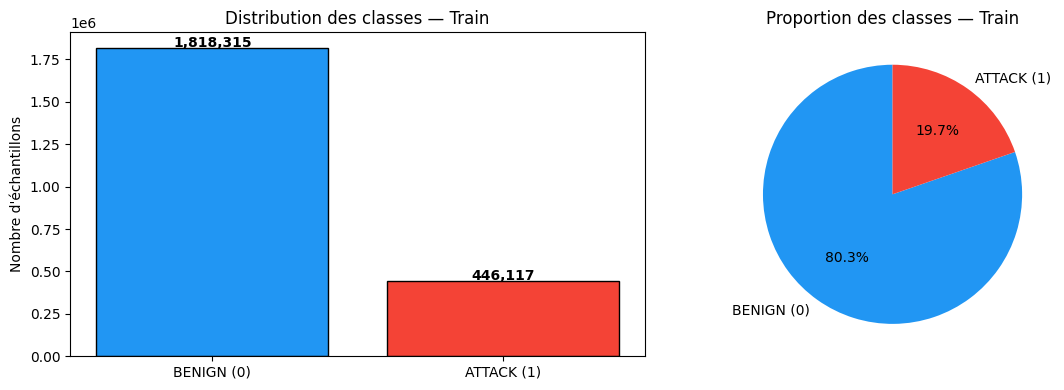

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\01_class_distribution.png


In [4]:
def save_and_show(nom, fig_dir=FIG_DIR):
    path = fig_dir / f"{nom}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 Sauvegardé : {path}")

counts = y_train.value_counts().sort_index()
labels = ['BENIGN (0)', 'ATTACK (1)']
colors = ['#2196F3', '#F44336']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(labels, counts.values, color=colors, edgecolor='black')
axes[0].set_title('Distribution des classes — Train')
axes[0].set_ylabel('Nombre d\'échantillons')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=labels, colors=colors,
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proportion des classes — Train')

save_and_show('01_class_distribution')


## 5. Préparation des Données pour CNN-BiLSTM

In [5]:
# Conversion NumPy
X_train_np = X_train.values.astype(np.float32)
X_test_np  = X_test.values.astype(np.float32)
y_train_np = y_train.values.astype(np.int32)
y_test_np  = y_test.values.astype(np.int32)

N_FEATURES = X_train_np.shape[1]
print(f"Nombre de features : {N_FEATURES}")

# Reshape pour Conv1D : (samples, timesteps, channels) → (samples, N_FEATURES, 1)
X_train_3d = X_train_np.reshape(-1, N_FEATURES, 1)
X_test_3d  = X_test_np.reshape(-1, N_FEATURES, 1)

print(f"Shape X_train_3d : {X_train_3d.shape}")
print(f"Shape X_test_3d  : {X_test_3d.shape}")
print("✅ Reshape OK")

# Split train → train + validation (80/20 du train)
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_3d, y_train_np, test_size=0.2, random_state=42, stratify=y_train_np
)
print(f"\nTrain  : {X_tr.shape[0]:,} samples")
print(f"Val    : {X_val.shape[0]:,} samples")
print(f"Test   : {X_test_3d.shape[0]:,} samples")


Nombre de features : 45
Shape X_train_3d : (2264432, 45, 1)
Shape X_test_3d  : (566109, 45, 1)
✅ Reshape OK

Train  : 1,811,545 samples
Val    : 452,887 samples
Test   : 566,109 samples


## 6. Calcul des Class Weights

In [6]:
classes = np.unique(y_train_np)
weights = compute_class_weight('balanced', classes=classes, y=y_train_np)
class_weight_dict = dict(zip(classes, weights))

print("Class weights calculés :")
for cls, w in class_weight_dict.items():
    label = 'BENIGN' if cls == 0 else 'ATTACK'
    print(f"  Classe {cls} ({label}) : {w:.4f}")
print("✅ Class weights OK")


Class weights calculés :
  Classe 0 (BENIGN) : 0.6227
  Classe 1 (ATTACK) : 2.5379
✅ Class weights OK


## 7. Construction du Modèle CNN-BiLSTM

In [7]:
def build_cnn_bilstm_binary(n_features):
    model = Sequential([
        Input(shape=(n_features, 1)),

        # Bloc CNN 1
        Conv1D(64, kernel_size=3, padding='same'),
        BatchNormalization(),
        Activation('relu'),

        # Bloc CNN 2
        Conv1D(128, kernel_size=3, padding='same'),
        BatchNormalization(),
        Activation('relu'),
        MaxPooling1D(pool_size=2),

        # BiLSTM 1 — recurrent_dropout pour régulariser les connexions récurrentes
        Bidirectional(LSTM(128, return_sequences=True, recurrent_dropout=0.2)),

        # BiLSTM 2 — recurrent_dropout
        Bidirectional(LSTM(64, recurrent_dropout=0.2)),

        # Tête de classification
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ], name='CNN_BiLSTM_Binary')

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_bilstm_binary(N_FEATURES)
model.summary()
print("\n✅ Modèle construit")


Model: "CNN_BiLSTM_Binary"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 45, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 45, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 45, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 45, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 45, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 45, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 22, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 22, 256)             │         263,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 128)                 │         164,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 461,569 (1.76 MB)

 Trainable params: 461,185 (1.76 MB)

 Non-trainable params: 384 (1.50 KB)


✅ Modèle construit


## 8. Callbacks

In [8]:
callbacks = [
    EarlyStopping(
        monitor='val_loss', patience=3,
        restore_best_weights=True, verbose=1
    ),
    ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor='val_loss', save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-6, verbose=1
    )
]

print("Callbacks configurés :")
for cb in callbacks:
    print(f"  ✅ {cb.__class__.__name__}")


Callbacks configurés :
  ✅ EarlyStopping
  ✅ ModelCheckpoint
  ✅ ReduceLROnPlateau


## 9. Entraînement

In [9]:
BATCH_SIZE = 2048
EPOCHS     = 20

print(f"Batch size : {BATCH_SIZE}")
print(f"Epochs max : {EPOCHS}")
print(f"Train size : {X_tr.shape[0]:,}")
print("\n⏳ Début de l'entraînement...\n")

t_start = time.time()

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

t_total = time.time() - t_start

print(f"\n✅ Entraînement terminé en {t_total/60:.1f} minutes")
print(f"Epochs exécutées : {len(history.history['loss']) if 'history' in dir() else epochs_ran}")
print(f"Meilleure val_loss : {min(history.history['val_loss']):.4f}")
print(f"Meilleure val_accuracy : {max(history.history['val_accuracy']):.4f}")

Batch size : 2048
Epochs max : 20
Train size : 1,811,545

⏳ Début de l'entraînement...

Epoch 1/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8660 - loss: 0.3922
Epoch 1: val_loss improved from None to 0.28364, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5



Epoch 1: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5
885/885 ━━━━━━━━━━━━━━━━━━━━ 1359s 2s/step - accuracy: 0.8933 - loss: 0.2864 - val_accuracy: 0.8547 - val_loss: 0.2836 - learning_rate: 0.0010
Epoch 2/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9282 - loss: 0.1840
Epoch 2: val_loss improved from 0.28364 to 0.19202, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5



Epoch 2: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5
885/885 ━━━━━━━━━━━━━━━━━━━━ 2483s 3s/step - accuracy: 0.9320 - loss: 0.1746 - val_accuracy: 0.9245 - val_loss: 0.1920 - learning_rate: 0.0010
Epoch 3/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9398 - loss: 0.1563
Epoch 3: val_loss did not improve from 0.19202
885/885 ━━━━━━━━━━━━━━━━━━━━ 1363s 2s/step - accuracy: 0.9433 - loss: 0.1482 - val_accuracy: 0.8371 - val_loss: 0.2977 - learning_rate: 0.0010
Epoch 4/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9456 - loss: 0.1401
Epoch 4: val_loss did not improve from 0.19202
885/885 ━━━━━━━━━━━━━━━━━━━━ 1361s 2s/step - accuracy: 0.9434 - loss: 0.1424 - val_accuracy: 0.8814 - val_loss: 0.2446 - learning_rate: 0.0010
Epoch 5/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9494 - loss: 0.1287
Epoch 5: val_loss improved from 0.19202 to 0.16534, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\mod


Epoch 5: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5
885/885 ━━━━━━━━━━━━━━━━━━━━ 1384s 2s/step - accuracy: 0.9518 - loss: 0.1221 - val_accuracy: 0.9419 - val_loss: 0.1653 - learning_rate: 0.0010
Epoch 6/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9536 - loss: 0.1138
Epoch 6: val_loss did not improve from 0.16534
885/885 ━━━━━━━━━━━━━━━━━━━━ 1356s 2s/step - accuracy: 0.9552 - loss: 0.1110 - val_accuracy: 0.8724 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 7/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9553 - loss: 0.1070
Epoch 7: val_loss improved from 0.16534 to 0.15012, saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5



Epoch 7: finished saving model to C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5
885/885 ━━━━━━━━━━━━━━━━━━━━ 2684s 3s/step - accuracy: 0.9572 - loss: 0.1035 - val_accuracy: 0.9374 - val_loss: 0.1501 - learning_rate: 0.0010
Epoch 8/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9555 - loss: 0.1057
Epoch 8: val_loss did not improve from 0.15012
885/885 ━━━━━━━━━━━━━━━━━━━━ 1484s 2s/step - accuracy: 0.9571 - loss: 0.1018 - val_accuracy: 0.9404 - val_loss: 0.1622 - learning_rate: 0.0010
Epoch 9/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9597 - loss: 0.0942
Epoch 9: val_loss did not improve from 0.15012
885/885 ━━━━━━━━━━━━━━━━━━━━ 1361s 2s/step - accuracy: 0.9602 - loss: 0.0930 - val_accuracy: 0.9032 - val_loss: 0.2195 - learning_rate: 0.0010
Epoch 10/20
885/885 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9583 - loss: 0.0952
Epoch 10: val_loss did not improve from 0.15012

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.000500000

## 10. Courbes d'Apprentissage

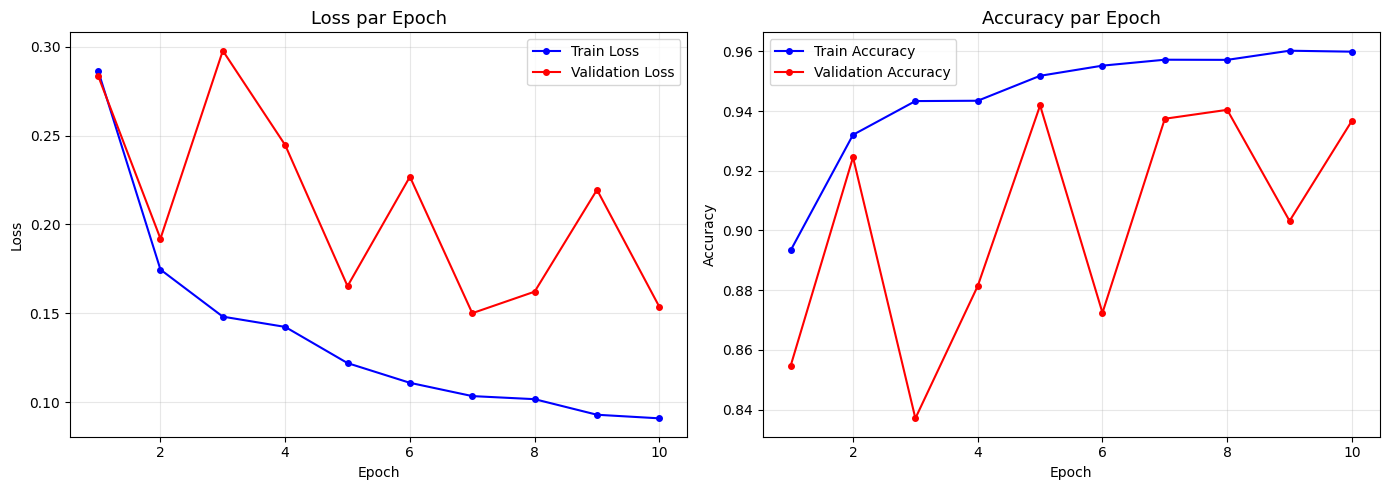

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\02_learning_curves.png


In [10]:
hist = history.history
epochs_ran = range(1, len(hist['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs_ran, hist['loss'],     'b-o', label='Train Loss',      ms=4)
axes[0].plot(epochs_ran, hist['val_loss'], 'r-o', label='Validation Loss', ms=4)
axes[0].set_title('Loss par Epoch', fontsize=13)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(epochs_ran, hist['accuracy'],     'b-o', label='Train Accuracy',      ms=4)
axes[1].plot(epochs_ran, hist['val_accuracy'], 'r-o', label='Validation Accuracy', ms=4)
axes[1].set_title('Accuracy par Epoch', fontsize=13)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

save_and_show('02_learning_curves')


## 11. Évaluation — Métriques Complètes

In [11]:
def evaluate_binary(model, X, y, split_name):
    """Calcule toutes les métriques pour un split donné."""
    y_prob = model.predict(X, batch_size=2048, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        'split'    : split_name,
        'accuracy' : accuracy_score(y, y_pred),
        'f1'       : f1_score(y, y_pred, average='weighted'),
        'precision': precision_score(y, y_pred, average='weighted'),
        'recall'   : recall_score(y, y_pred, average='weighted'),
        'roc_auc'  : roc_auc_score(y, y_prob)
    }
    return metrics, y_pred, y_prob

print("⏳ Évaluation en cours...\n")

metrics_tr,  y_pred_tr,  y_prob_tr  = evaluate_binary(model, X_tr,       y_tr,       'Train')
metrics_val, y_pred_val, y_prob_val = evaluate_binary(model, X_val,      y_val,      'Validation')
metrics_te,  y_pred_te,  y_prob_te  = evaluate_binary(model, X_test_3d,  y_test_np,  'Test')

all_metrics = [metrics_tr, metrics_val, metrics_te]
df_metrics  = pd.DataFrame(all_metrics)

print("=" * 70)
print(df_metrics.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print("=" * 70)

# Vérification des cibles
print(f"\n🎯 Accuracy Test  : {metrics_te['accuracy']:.4f} {'✅' if metrics_te['accuracy']>0.98 else '⚠️'} (cible >98%)")
print(f"🎯 F1-score Test   : {metrics_te['f1']:.4f} {'✅' if metrics_te['f1']>0.97 else '⚠️'} (cible >97%)")

# Classification report complet
print("\n── Classification Report (Test) ──")
print(classification_report(y_test_np, y_pred_te, target_names=['BENIGN', 'ATTACK']))


⏳ Évaluation en cours...

     split  accuracy     f1  precision  recall  roc_auc
     Train    0.9381 0.9405     0.9488  0.9381   0.9898
Validation    0.9374 0.9399     0.9483  0.9374   0.9896
      Test    0.9377 0.9402     0.9485  0.9377   0.9898

🎯 Accuracy Test  : 0.9377 ⚠️ (cible >98%)
🎯 F1-score Test   : 0.9402 ⚠️ (cible >97%)

── Classification Report (Test) ──
              precision    recall  f1-score   support

      BENIGN       0.99      0.93      0.96    454580
      ATTACK       0.77      0.97      0.86    111529

    accuracy                           0.94    566109
   macro avg       0.88      0.95      0.91    566109
weighted avg       0.95      0.94      0.94    566109



## 12. Visualisation — Tableau Métriques Comparatif

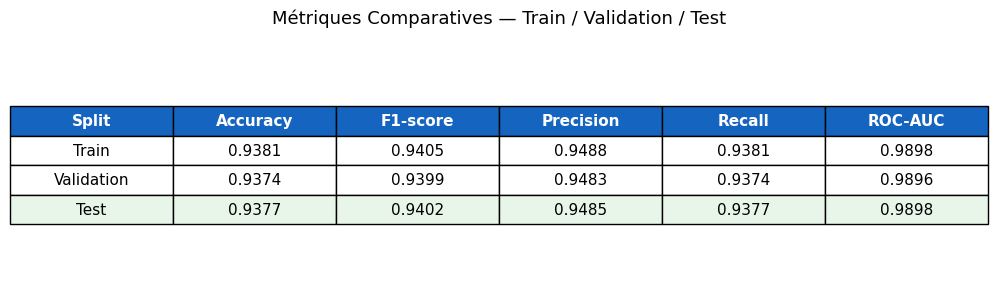

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\03_metrics_table.png


In [12]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

cols = ['Split', 'Accuracy', 'F1-score', 'Precision', 'Recall', 'ROC-AUC']
rows = []
for m in all_metrics:
    rows.append([
        m['split'],
        f"{m['accuracy']:.4f}",
        f"{m['f1']:.4f}",
        f"{m['precision']:.4f}",
        f"{m['recall']:.4f}",
        f"{m['roc_auc']:.4f}"
    ])

table = ax.table(cellText=rows, colLabels=cols,
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

# Colorier l'entête
for j in range(len(cols)):
    table[0, j].set_facecolor('#1565C0')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Colorier Test en vert clair
for j in range(len(cols)):
    table[3, j].set_facecolor('#E8F5E9')

plt.title('Métriques Comparatives — Train / Validation / Test', fontsize=13, pad=20)
save_and_show('03_metrics_table')


## 13. Matrice de Confusion

Taux de Faux Positifs : 0.0696 (6.96%) ⚠️ (cible <1%)
Vrais Positifs        : 107,918
Vrais Négatifs        : 422,929
Faux Positifs         : 31,651
Faux Négatifs         : 3,611


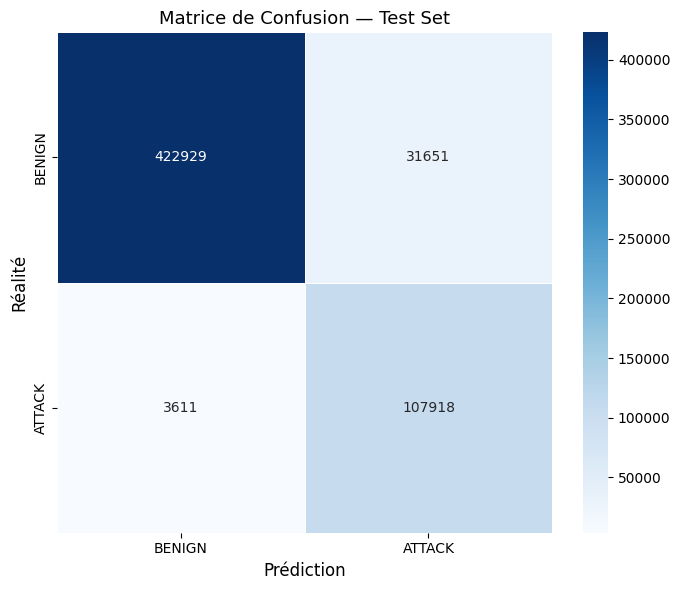

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\04_confusion_matrix.png


In [13]:
cm = confusion_matrix(y_test_np, y_pred_te)

# Taux de faux positifs
tn, fp, fn, tp = cm.ravel()
fpr_val = fp / (fp + tn)
print(f"Taux de Faux Positifs : {fpr_val:.4f} ({fpr_val*100:.2f}%) {'✅' if fpr_val<0.01 else '⚠️'} (cible <1%)")
print(f"Vrais Positifs        : {tp:,}")
print(f"Vrais Négatifs        : {tn:,}")
print(f"Faux Positifs         : {fp:,}")
print(f"Faux Négatifs         : {fn:,}")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['BENIGN', 'ATTACK'],
            yticklabels=['BENIGN', 'ATTACK'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Prédiction', fontsize=12)
ax.set_ylabel('Réalité', fontsize=12)
ax.set_title('Matrice de Confusion — Test Set', fontsize=13)
save_and_show('04_confusion_matrix')


## 14. Courbe ROC

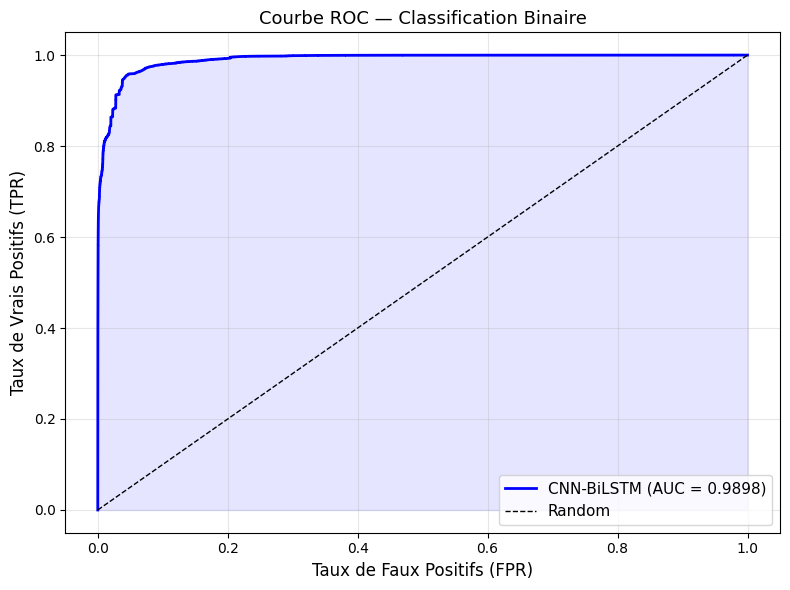

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\05_roc_curve.png


In [14]:
fpr, tpr, thresholds = roc_curve(y_test_np, y_prob_te)
auc_score = roc_auc_score(y_test_np, y_prob_te)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, 'b-', lw=2, label=f'CNN-BiLSTM (AUC = {auc_score:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.fill_between(fpr, tpr, alpha=0.1, color='blue')
ax.set_xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
ax.set_ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
ax.set_title('Courbe ROC — Classification Binaire', fontsize=13)
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
save_and_show('05_roc_curve')


## 15. Courbe Precision-Recall

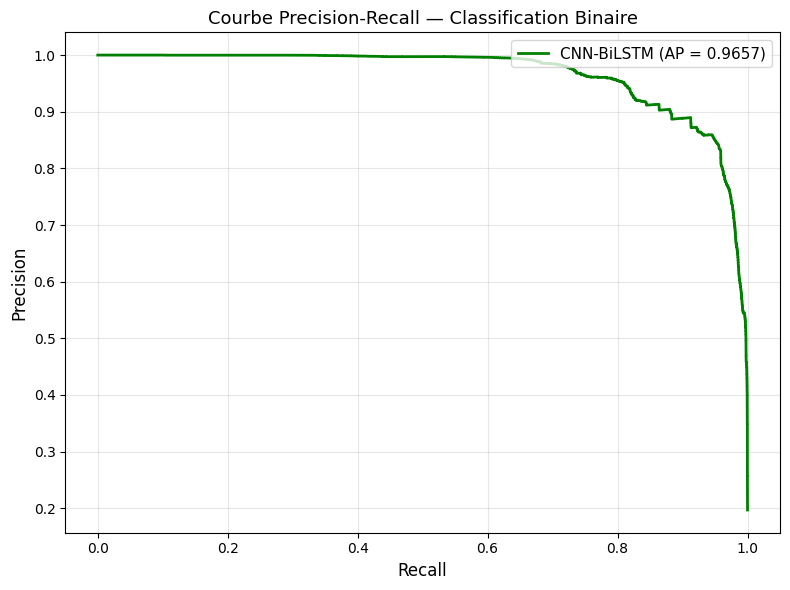

💾 Sauvegardé : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\figures\binary\06_precision_recall_curve.png


In [15]:
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_te)
ap_score = average_precision_score(y_test_np, y_prob_te)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_curve, precision_curve, 'g-', lw=2,
        label=f'CNN-BiLSTM (AP = {ap_score:.4f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Courbe Precision-Recall — Classification Binaire', fontsize=13)
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, alpha=0.3)
save_and_show('06_precision_recall_curve')


## 16. Sauvegarde des Métriques

In [16]:
# DataFrame métriques
df_metrics.to_csv(
    METRIC_DIR / f'binary_metrics_{TIMESTAMP}.csv',
    index=False
)

# JSON complet
metrics_json = {
    'model'    : 'CNN-BiLSTM-Binary',
    'timestamp': TIMESTAMP,
    'n_features': N_FEATURES,
    'epochs_ran': len(history.history['loss']) if 'history' in dir() else epochs_ran,
    'splits'   : all_metrics
}
with open(METRIC_DIR / f'binary_metrics_{TIMESTAMP}.json', 'w') as f:
    json.dump(metrics_json, f, indent=2)

# Sauvegarde modèle (déjà fait par ModelCheckpoint, mais on force)
model.save(str(MODEL_PATH))

print(f"✅ Métriques CSV  : {METRIC_DIR}/binary_metrics_{TIMESTAMP}.csv")
print(f"✅ Métriques JSON : {METRIC_DIR}/binary_metrics_{TIMESTAMP}.json")
print(f"✅ Modèle sauvé   : {MODEL_PATH}")


✅ Métriques CSV  : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\metrics/binary_metrics_20260615_193530.csv
✅ Métriques JSON : C:\Users\lenovo\Desktop\Nouveau dossier (3)\results\metrics/binary_metrics_20260615_193530.json
✅ Modèle sauvé   : C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5


## 17. Résumé Final

In [17]:
print("=" * 65)
print("      RÉSUMÉ — CNN-BiLSTM Classification Binaire")
print("=" * 65)
print(f"  Dataset        : CIC-IDS2017 (binaire)")
print(f"  Features       : {N_FEATURES}")
print(f"  Epochs réels   : {len(history.history['loss']) if 'history' in dir() else epochs_ran}")
print(f"  Batch size     : {BATCH_SIZE}")
print()
for m in all_metrics:
    print(f"  [{m['split']:>12}]  Acc={m['accuracy']:.4f}  F1={m['f1']:.4f}  AUC={m['roc_auc']:.4f}")
print()
print(f"  Modèle : {MODEL_PATH}")
print("=" * 65)


      RÉSUMÉ — CNN-BiLSTM Classification Binaire
  Dataset        : CIC-IDS2017 (binaire)
  Features       : 45
  Epochs réels   : 10
  Batch size     : 2048

  [       Train]  Acc=0.9381  F1=0.9405  AUC=0.9898
  [  Validation]  Acc=0.9374  F1=0.9399  AUC=0.9896
  [        Test]  Acc=0.9377  F1=0.9402  AUC=0.9898

  Modèle : C:\Users\lenovo\Desktop\Nouveau dossier (3)\models\cnn_bilstm_binary.h5
